In [24]:
!pip install librosa soundfile scikit-learn joblib numpy pandas tqdm matplotlib seaborn


In [25]:
import os
import numpy as np
import librosa
import joblib
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import matplotlib.pyplot as plt
import seaborn as sns


In [9]:
!wget "https://zenodo.org/record/1188976/files/Audio_Speech_Actors_01-24.zip?download=1" -O ravdess.zip





--2026-01-26 05:41:00--  https://zenodo.org/record/1188976/files/Audio_Speech_Actors_01-24.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.52.235, 188.185.48.75, 188.185.43.153, ...
Connecting to zenodo.org (zenodo.org)|137.138.52.235|:443... connected.
HTTP request sent, awaiting response... 301 MOVED PERMANENTLY
Location: /records/1188976/files/Audio_Speech_Actors_01-24.zip [following]
--2026-01-26 05:41:01--  https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip
Reusing existing connection to zenodo.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 208468073 (199M) [application/octet-stream]
Saving to: ‘ravdess.zip’

ravdess.zip         100%[===================>] 198.81M  2.09MB/s    in 87s     

2026-01-26 05:42:29 (2.28 MB/s) - ‘ravdess.zip’ saved [208468073/208468073]



In [10]:
!unzip ravdess.zip


Archive:  ravdess.zip
   creating: Actor_01/
  inflating: Actor_01/03-01-01-01-01-01-01.wav  
  inflating: Actor_01/03-01-01-01-01-02-01.wav  
  inflating: Actor_01/03-01-01-01-02-01-01.wav  
  inflating: Actor_01/03-01-01-01-02-02-01.wav  
  inflating: Actor_01/03-01-02-01-01-01-01.wav  
  inflating: Actor_01/03-01-02-01-01-02-01.wav  
  inflating: Actor_01/03-01-02-01-02-01-01.wav  
  inflating: Actor_01/03-01-02-01-02-02-01.wav  
  inflating: Actor_01/03-01-02-02-01-01-01.wav  
  inflating: Actor_01/03-01-02-02-01-02-01.wav  
  inflating: Actor_01/03-01-02-02-02-01-01.wav  
  inflating: Actor_01/03-01-02-02-02-02-01.wav  
  inflating: Actor_01/03-01-03-01-01-01-01.wav  
  inflating: Actor_01/03-01-03-01-01-02-01.wav  
  inflating: Actor_01/03-01-03-01-02-01-01.wav  
  inflating: Actor_01/03-01-03-01-02-02-01.wav  
  inflating: Actor_01/03-01-03-02-01-01-01.wav  
  inflating: Actor_01/03-01-03-02-01-02-01.wav  
  inflating: Actor_01/03-01-03-02-02-01-01.wav  
  inflating: Actor_01/03

In [27]:
BASE_DIR = "."
SAMPLE_RATE = 22050
N_MFCC = 40


In [26]:
EMOTION_TO_STRESS = {
    "01": "Calm",        # Neutral
    "02": "Calm",        # Calm
    "03": "Mild",        # Happy
    "04": "Mild",        # Sad
    "05": "Escalated",   # Angry
    "06": "Escalated",   # Fearful
    "07": "Escalated",   # Disgust
    "08": "Mild"         # Surprise
}


In [28]:
def extract_mfcc(filepath, n_mfcc=40):
    signal, sr = librosa.load(filepath, sr=SAMPLE_RATE)
    mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=n_mfcc)
    mfcc_mean = np.mean(mfcc.T, axis=0)
    mfcc_std = np.std(mfcc.T, axis=0)
    return np.hstack([mfcc_mean, mfcc_std])


X = np.array(X)
y = np.array(y)

print(X.shape, y.shape)


(1440, 40) (1440,)


In [29]:
X, y = [], []

for actor in tqdm(sorted(os.listdir(BASE_DIR))):
    if not actor.startswith("Actor"):
        continue

    actor_path = os.path.join(BASE_DIR, actor)

    for file in os.listdir(actor_path):
        if not file.endswith(".wav"):
            continue

        emotion_code = file.split("-")[2]
        if emotion_code not in EMOTION_TO_STRESS:
            continue

        label = EMOTION_TO_STRESS[emotion_code]
        filepath = os.path.join(actor_path, file)

        features = extract_mfcc(filepath)
        X.append(features)
        y.append(label)

X = np.array(X)
y = np.array(y)

print("Feature shape:", X.shape)
print("Label distribution:", dict(zip(*np.unique(y, return_counts=True))))


100%|██████████| 28/28 [00:45<00:00,  1.62s/it]

Feature shape: (1440, 80)
Label distribution: {np.str_('Calm'): np.int64(288), np.str_('Escalated'): np.int64(576), np.str_('Mild'): np.int64(576)}


In [30]:
le = LabelEncoder()
y_enc = le.fit_transform(y)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Encoded classes:", le.classes_)


Encoded classes: ['Calm' 'Escalated' 'Mild']


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y_enc,
    test_size=0.2,
    stratify=y_enc,
    random_state=42
)


In [32]:
clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    class_weight="balanced",
    random_state=42
)

clf.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', max_depth=20, n_estimators=300,
                       random_state=42)

In [33]:
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))


Accuracy: 0.7881944444444444

Classification Report:

              precision    recall  f1-score   support

        Calm       0.82      0.88      0.85        58
   Escalated       0.83      0.76      0.79       115
        Mild       0.74      0.77      0.75       115

    accuracy                           0.79       288
   macro avg       0.80      0.80      0.80       288
weighted avg       0.79      0.79      0.79       288



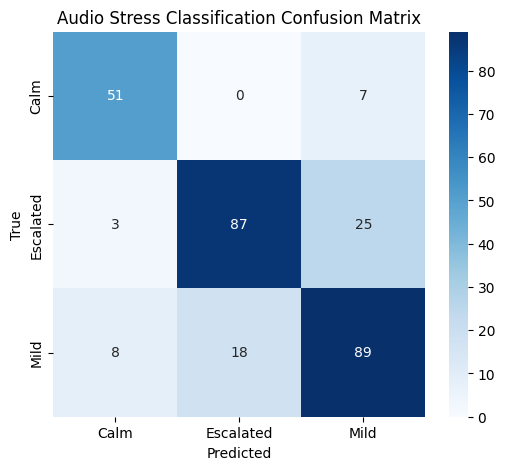

In [34]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Audio Stress Classification Confusion Matrix")
plt.show()



In [35]:
joblib.dump(clf, "audio_stress_model.pkl")
joblib.dump(scaler, "audio_scaler.pkl")
joblib.dump(le, "audio_label_encoder.pkl")

print("Audio stress model artifacts saved.")


Audio stress model artifacts saved.


In [36]:
from google.colab import files

files.download("audio_stress_model.pkl")
files.download("audio_scaler.pkl")
files.download("audio_label_encoder.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>